In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

# Load the dataset
df = pd.read_csv("/content/measures_v2 (1).csv")

# Basic dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDescriptive statistics:")
print(df.describe().T)

print("\nNumber of profiles:", df["profile_id"].nunique())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (1330816, 13)

Column names:
['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330816 entries, 0 to 1330815
Data columns (total 13 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   u_q             1330816 non-null  float64
 1   coolant         1330816 non-null  float64
 2   stator_winding  1330816 non-null  float64
 3   u_d             1330816 non-null  float64
 4   stator_tooth    1330816 non-null  float64
 5   motor_speed     1330816 non-null  float64
 6   i_d             1330816 non-null  float64
 7   i_q             1330816 non-null  float64
 8   pm              1330816 non-null  float64
 9   stator_yoke     1330816 n

In [41]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [42]:
# Check the extreme values in important columns
print("Motor speed range:")
print(df["motor_speed"].min(), df["motor_speed"].max())

print("\nTorque range:")
print(df["torque"].min(), df["torque"].max())

print("\nWinding temperature range:")
print(df["stator_winding"].min(), df["stator_winding"].max())

Motor speed range:
-275.54914411131955 6000.01513671875

Torque range:
-246.46666318909087 261.0057067871094

Winding temperature range:
18.5858154296875 141.36288452148438


In [43]:
# Investigate high winding temperatures
threshold = 120

hot_rows = df[df["stator_winding"] > threshold]

print("Observations above 120°C:", len(hot_rows))
print("Percentage of dataset:",
      round(len(hot_rows) / len(df) * 100, 4), "%")

print("\nHighest winding temperatures:")
print(df["stator_winding"].nlargest(10).to_list())

Observations above 120°C: 45295
Percentage of dataset: 3.4036 %

Highest winding temperatures:
[141.36288452148438, 141.31109619140625, 141.28977966308594, 141.1876220703125, 141.1787567138672, 141.1649932861328, 141.12928771972656, 141.10971069335938, 141.03829956054688, 141.03512573242188]


In [44]:
print("Negative motor speed:",
      (df["motor_speed"] < 0).sum())

print("Negative torque:",
      (df["torque"] < 0).sum())

Negative motor speed: 87308
Negative torque: 446946


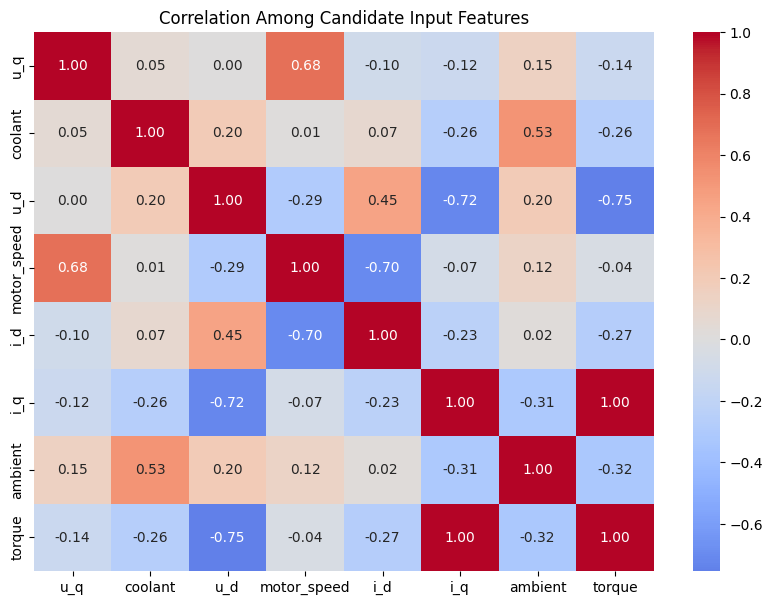

In [45]:
excluded = [
    "stator_tooth",
    "stator_yoke",
    "pm",
    "stator_winding",
    "profile_id"
]

candidate_features = df.drop(columns=excluded)

corr = candidate_features.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Among Candidate Input Features")
plt.show()

In [46]:
print(
    "Exact correlation between i_q and torque:",
    df["i_q"].corr(df["torque"])
)

Exact correlation between i_q and torque: 0.9964572617652482


In [47]:
# Analyze all motor profiles
profile_summary = df.groupby("profile_id")["stator_winding"].agg(
    ["mean", "min", "max", "count"]
)

print("Number of profiles:", len(profile_summary))
print(profile_summary)

Number of profiles: 69
                 mean        min         max  count
profile_id                                         
2           51.110270  19.428793  103.282516  19357
3           29.033779  19.179312   39.101830  19248
4           46.010193  18.585815  113.379204  33424
5           30.747415  19.058098   43.397926  14788
6           70.843022  19.033159  121.034332  40388
...               ...        ...         ...    ...
76          73.277884  28.031018  117.889581  22188
78          68.506249  19.173869  100.850035   8445
79          77.292279  23.632647  128.246583  31154
80          78.049261  24.560353  121.097685  23824
81          64.521898  23.601342  104.655582  17672

[69 rows x 4 columns]


In [48]:
# Calculate the magnitude of the motor current
df["current_magnitude"] = np.sqrt(
    df["i_d"]**2 + df["i_q"]**2
)

print("Current magnitude statistics:")
print(df["current_magnitude"].describe())

print("\nCorrelation with stator winding temperature:")
print(
    df["current_magnitude"].corr(df["stator_winding"])
)

Current magnitude statistics:
count    1.330816e+06
mean     1.075446e+02
std      8.526254e+01
min      3.922213e-05
25%      1.182819e+01
50%      1.106200e+02
75%      1.721419e+02
max      3.615153e+02
Name: current_magnitude, dtype: float64

Correlation with stator winding temperature:
0.571575082855501


In [49]:
# Document the team's feature exclusions
excluded_features = ["stator_tooth", "stator_yoke", "pm"]
target = "stator_winding"

candidate_features = [
    col for col in df.columns
    if col not in excluded_features + [target]
]

print("Target variable:", target)
print("Features excluded by team:", excluded_features)
print("Candidate input features:", candidate_features)
print("Number of candidate input features:", len(candidate_features))

Target variable: stator_winding
Features excluded by team: ['stator_tooth', 'stator_yoke', 'pm']
Candidate input features: ['u_q', 'coolant', 'u_d', 'motor_speed', 'i_d', 'i_q', 'ambient', 'torque', 'profile_id', 'current_magnitude']
Number of candidate input features: 10


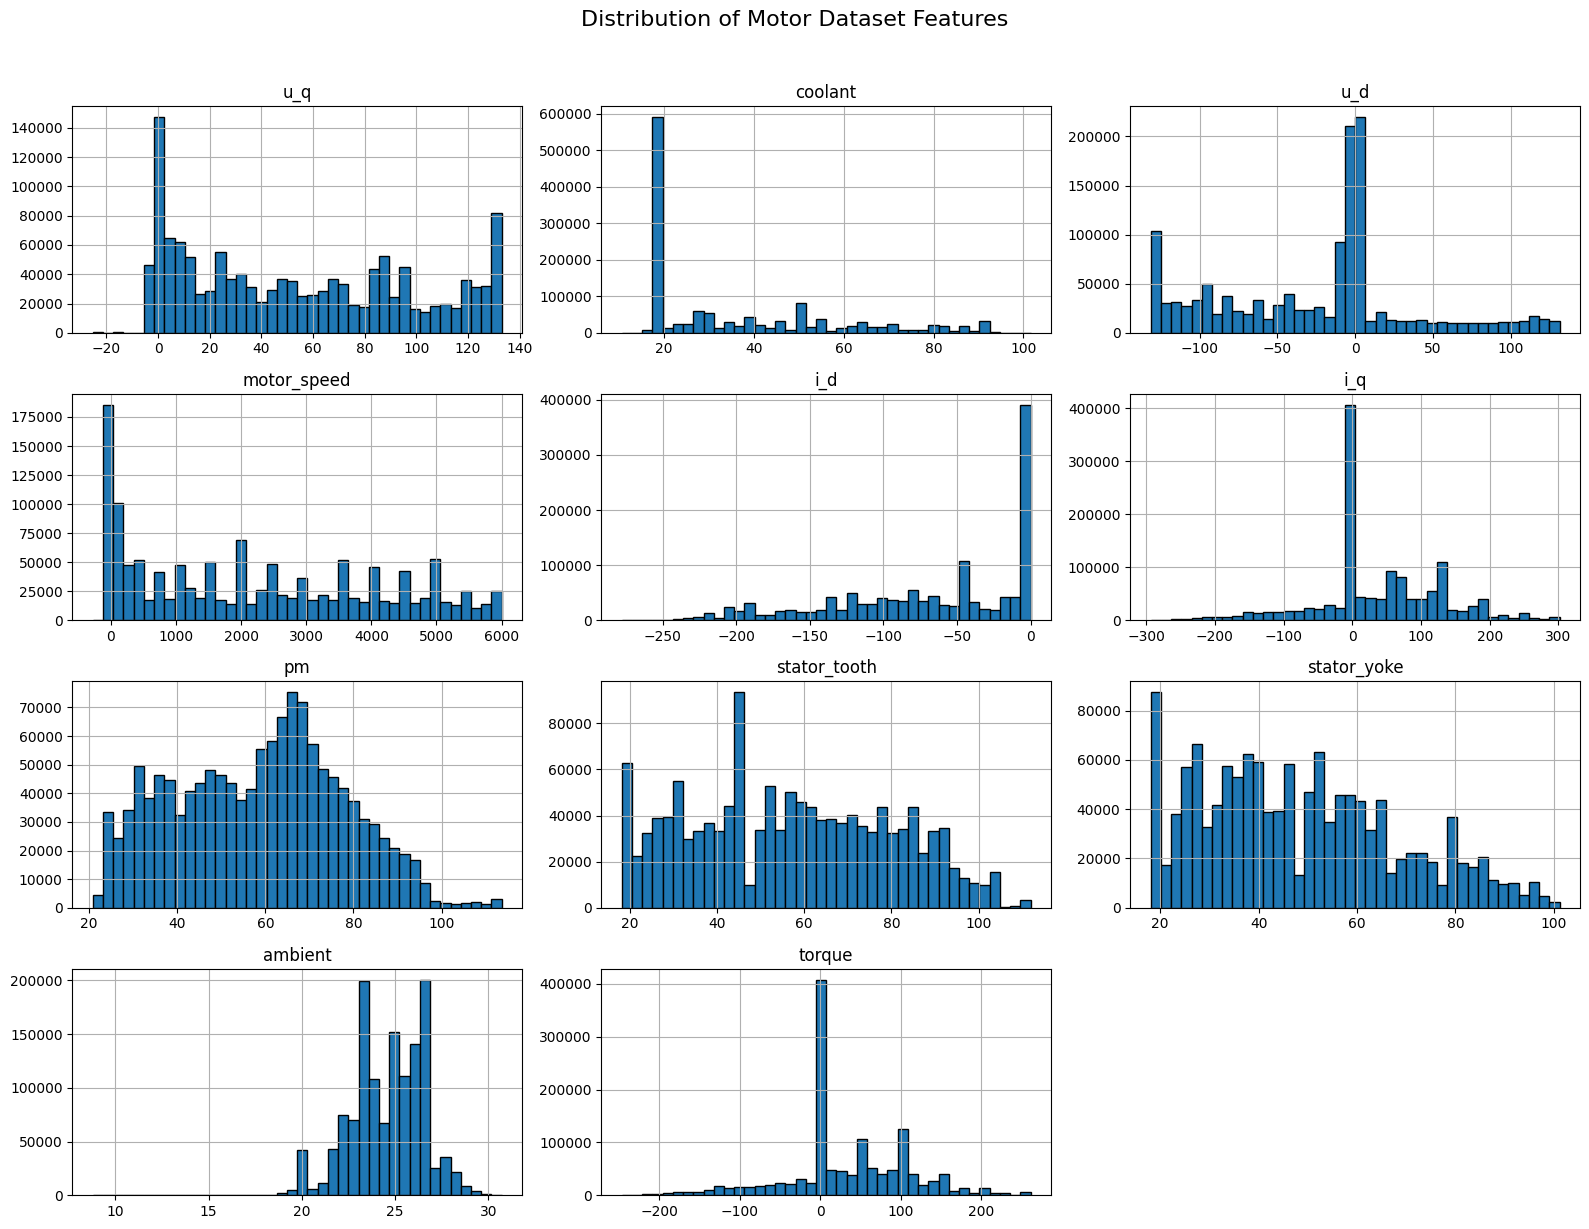

In [50]:
# Histograms of features to understand their distributions

features_to_plot = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "pm",
    "stator_tooth",
    "stator_yoke",
    "ambient",
    "torque"
]

df[features_to_plot].hist(
    bins=40,
    figsize=(16, 12),
    layout=(4, 3),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Motor Dataset Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

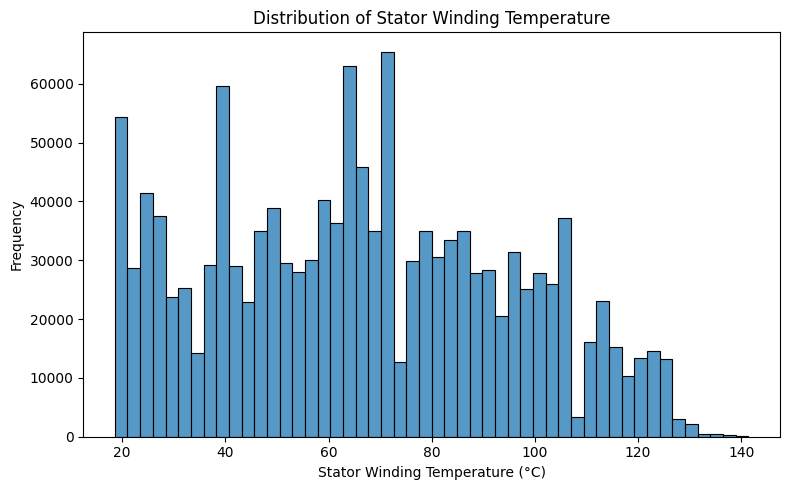

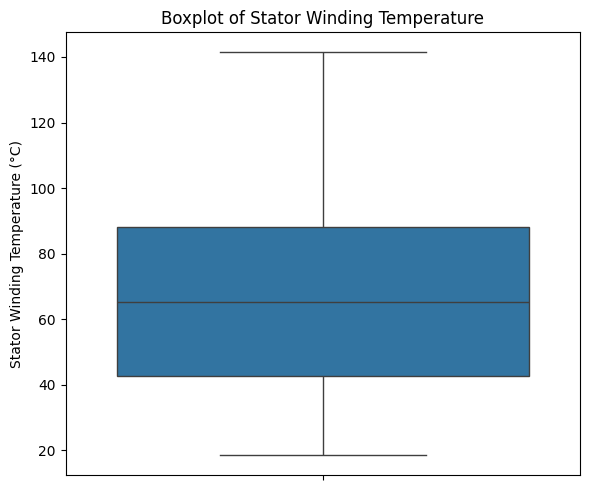

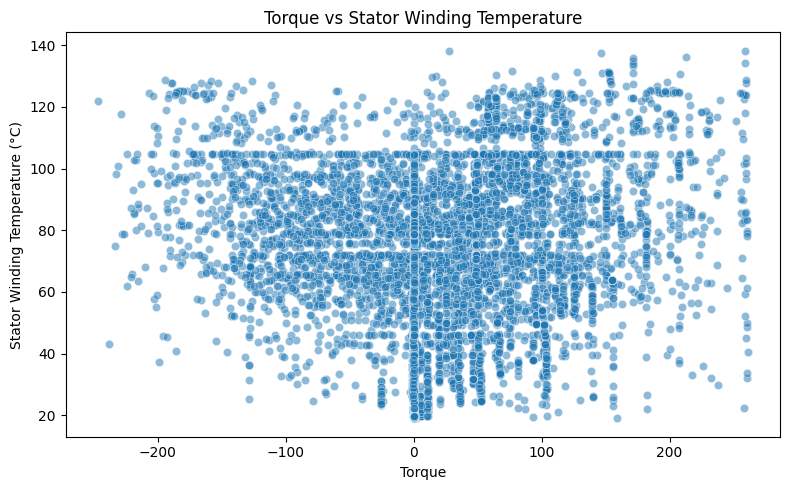

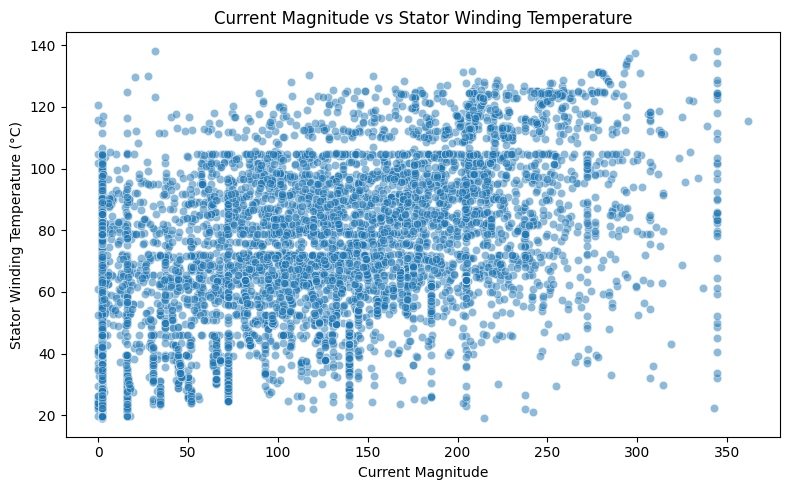

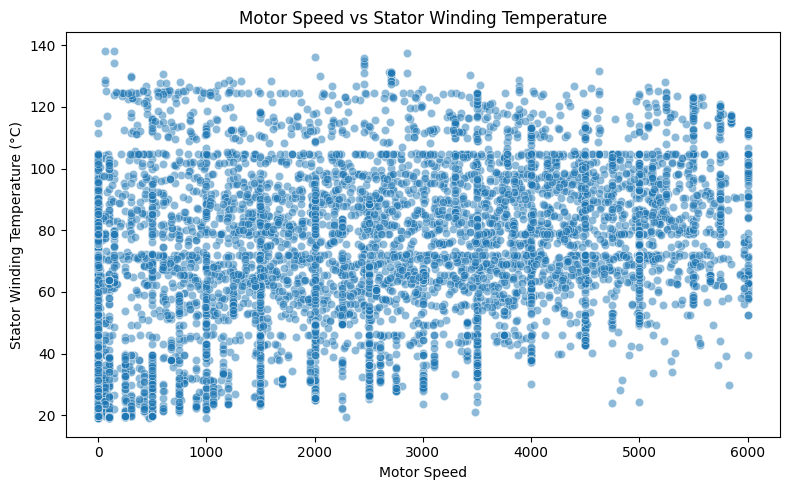

In [51]:
# 1. Distribution of target temperature
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="stator_winding", bins=50)

plt.title("Distribution of Stator Winding Temperature")
plt.xlabel("Stator Winding Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 2. Boxplot of target temperature
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, y="stator_winding")

plt.title("Boxplot of Stator Winding Temperature")
plt.ylabel("Stator Winding Temperature (°C)")
plt.tight_layout()
plt.show()


# Use the same random sample for the scatterplots
sample_df = df.sample(10000, random_state=42)


# 3. Torque vs target temperature
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="torque",
    y="stator_winding",
    alpha=0.5
)

plt.title("Torque vs Stator Winding Temperature")
plt.xlabel("Torque")
plt.ylabel("Stator Winding Temperature (°C)")
plt.tight_layout()
plt.show()


# 4. Current magnitude vs target temperature
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="current_magnitude",
    y="stator_winding",
    alpha=0.5
)

plt.title("Current Magnitude vs Stator Winding Temperature")
plt.xlabel("Current Magnitude")
plt.ylabel("Stator Winding Temperature (°C)")
plt.tight_layout()
plt.show()


# 5. Motor speed vs target temperature
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="motor_speed",
    y="stator_winding",
    alpha=0.5
)

plt.title("Motor Speed vs Stator Winding Temperature")
plt.xlabel("Motor Speed")
plt.ylabel("Stator Winding Temperature (°C)")
plt.tight_layout()
plt.show()